# Print

In [4]:
print("Hello World")

Hello World


# Variable

In [5]:
a = 5
b = 7
item = "bike" # item is the variable name
print("Sum =", a + b)
print(item)
print(a)

Sum = 12
bike
5


In [3]:
import numpy as np
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 1. 載入鳶尾花資料集
iris = datasets.load_iris()
X = iris.data    # 特徵資料（如花瓣長度、寬度等）
y = iris.target  # 目標標籤（花的種類）

# 2. 切割資料集（80% 作為訓練集，20% 作為測試集）
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. 初始化 KNN 分類器
# 這裡設定 K 值為 3 (n_neighbors=3)
# 預設使用的是歐氏距離 (metric='minkowski', p=2 即為歐氏距離)
knn = KNeighborsClassifier(n_neighbors=3)

# 4. 訓練模型
knn.fit(X_train, y_train)

# 5. 使用測試集進行預測
y_pred = knn.predict(X_test)

# 6. 評估模型準確率
accuracy = accuracy_score(y_test, y_pred)
print(f"模型預測準確率: {accuracy * 100:.2f}%")

# 7. 測試一筆新資料
# 假設我們量到一朵花，四個特徵數值分別是 5.1, 3.5, 1.4, 0.2
new_flower = np.array([[5.1, 3.5, 1.4, 0.2]])
prediction = knn.predict(new_flower)
print(f"新花朵的預測類別: {iris.target_names[prediction[0]]}")


模型預測準確率: 100.00%
新花朵的預測類別: setosa


--- Model Evaluation ---
Accuracy Score: 0.9833

Confusion Matrix:
 [[18  1]
 [ 0 41]]

Classification Report:
               precision    recall  f1-score   support

         0.0       1.00      0.95      0.97        19
         1.0       0.98      1.00      0.99        41

    accuracy                           0.98        60
   macro avg       0.99      0.97      0.98        60
weighted avg       0.98      0.98      0.98        60



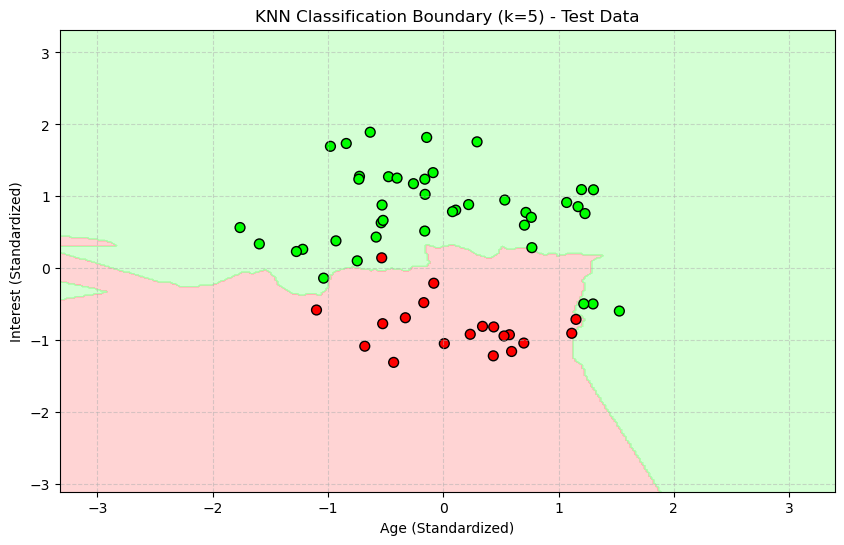

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from matplotlib.colors import ListedColormap

# 1. Load the data
# Ensure 'age_interest_success.csv' is in the same directory as your Jupyter Notebook
file_path = "/Users/joey/Downloads/age_interest_success.csv"
df = pd.read_csv(file_path)

# 2. Separate features (X) and target (y)
X = df[['age', 'interest']]
y = df['success']

# 3. Split the data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Scale the features
# KNN relies on distance metrics (like Euclidean), so standardizing features is highly recommended
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Initialize the K-Nearest Neighbors Classifier
# We start with k=5, but you can adjust this hyperparameter to see how it affects performance
knn = KNeighborsClassifier(n_neighbors=5)

# 6. Fit the model to the training data
knn.fit(X_train_scaled, y_train)

# 7. Predict on the test data
y_pred = knn.predict(X_test_scaled)

# 8. Evaluate the model
print("--- Model Evaluation ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# 9. Visualize the decision boundary (Optional but helpful)
# Create a mesh grid over the scaled feature space
x_min, x_max = X_train_scaled[:, 0].min() - 1, X_train_scaled[:, 0].max() + 1
y_min, y_max = X_train_scaled[:, 1].min() - 1, X_train_scaled[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

# Predict classifications across the entire grid
Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot the contour map and overlay the test data points
plt.figure(figsize=(10, 6))
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00'])

plt.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.5)
plt.scatter(X_test_scaled[:, 0], X_test_scaled[:, 1], c=y_test, cmap=cmap_bold, edgecolor='k', s=50)

plt.title("KNN Classification Boundary (k=5) - Test Data")
plt.xlabel("Age (Standardized)")
plt.ylabel("Interest (Standardized)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()
